Setup data

# Thư viện cần thiết:

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [2]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT_PATH = "/content/drive/MyDrive/AI_Project"

DATA_PATH = f"{PROJECT_PATH}/data"

Mounted at /content/drive


In [3]:
import pandas as pd

data = pd.read_csv(
    f"{DATA_PATH}/final_balanced_dataset.csv",
    encoding='utf-8'
)
data.head()

,text,label
0,Mùi hơi hôi khi ăn không như các yến mạch khác.,NEGATIVE
1,Dung voi mo ta:size co van de Chat lieu:tot Ma...,NEGATIVE
2,Thời gian giao hàng nhanh :).,POSITIVE
3,Dặn shop gửi 3 màu khác nhau thì lại giao 3 cá...,NEGATIVE
4,Giống hình mà vải hơi cứng bạn ạk.,POSITIVE


# **PHẦN A — TIỀN XỬ LÝ & PHÂN TÍCH VĂN BẢN**

## **A.1 Khám phá dữ liệu ban đầu**

---

###Câu A1

- Tải dữ liệu và hiển thị 10 dòng đầu.

- Mô tả cấu trúc DataFrame: số cột, kiểu dữ liệu từng cột, số lượng mẫu theo từng nhãn.

- Nhận xét xem dữ liệu có bị mất cân bằng (imbalanced) không? Nếu có, điều này ảnh hưởng như thế nào đến quá trình huấn luyện mô hình?

---

- Xem số dòng và số cột:

In [4]:
print(f"Kích thước dữ liệu: {data.shape[0]} dòng, {data.shape[1]} cột")
display(data.head(10))

Kích thước dữ liệu: 21868 dòng, 2 cột


,text,label
0,Mùi hơi hôi khi ăn không như các yến mạch khác.,NEGATIVE
1,Dung voi mo ta:size co van de Chat lieu:tot Ma...,NEGATIVE
2,Thời gian giao hàng nhanh :).,POSITIVE
3,Dặn shop gửi 3 màu khác nhau thì lại giao 3 cá...,NEGATIVE
4,Giống hình mà vải hơi cứng bạn ạk.,POSITIVE
5,Cong dung:duong toc Danh cho toc:tao kieu toc ...,POSITIVE
6,Sẽ còn ủng hộ shop dài dài 😍😍😍.,POSITIVE
7,"lúc đầu mình mua về cảm thấy rất ưng ý,nghe êm...",NEUTRAL
8,Size hơi to nhỉ 45kg -1m50 size S rồi mà hơi r...,POSITIVE
9,Hàng ok.,NEUTRAL


Mô tả cấu trúc DataFrame:
- **Số lượng dòng:** 21,868 dòng.
- **Số lượng cột:** 4 cột (bao gồm 2 cột gốc `text`, `label` và 2 cột đặc trưng vừa tạo `word_count`, `char_count`).
- **Kiểu dữ liệu:** Cột văn bản và nhãn là kiểu `object`, cột độ dài là kiểu `int64`.

- Xem kiểu dữ liệu từng cột:

In [5]:
print(data.dtypes)

text     object
label    object
dtype: object


- Xem tổng quan hơn:

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21868 entries, 0 to 21867
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    21868 non-null  object
 1   label   21868 non-null  object
dtypes: object(2)
memory usage: 341.8+ KB


**Số lượng mẫu thực tế theo từng nhãn (label):**

In [7]:
data["label"].value_counts().sort_index()

,count
label,
NEGATIVE,7346
NEUTRAL,6312
POSITIVE,7971
SPAM,239


Trực quan

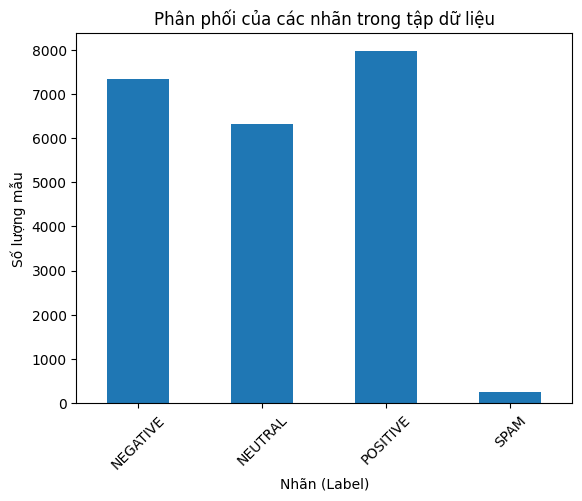

In [8]:
import matplotlib.pyplot as plt

# Vẽ biểu đồ phân phối nhãn
data["label"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Nhãn (Label)")
plt.ylabel("Số lượng mẫu")
plt.title("Phân phối của các nhãn trong tập dữ liệu")
plt.xticks(rotation=45)
plt.show()


Nhận xét mất cân bằng dữ liệu:
- Trong dữ liệu, các nhãn POSITIVE, NEGATIVE và NEUTRAL có số lượng khá tương đồng (dao động từ 6.300 đến gần 8.000 mẫu).
- Tuy nhiên, nhãn **SPAM** chỉ có 239 mẫu, chiếm tỷ lệ cực kỳ thấp so với các nhóm còn lại. Điều này cho thấy tập dữ liệu bị mất cân bằng nghiêm trọng ở lớp SPAM.



Ảnh hưởng đến huấn luyện mô hình:
- Dữ liệu mất cân bằng khiến mô hình có xu hướng ưu tiên dự đoán các lớp đa số (POSITIVE, NEGATIVE, NEUTRAL).
- **Độ chính xác (Accuracy) ảo:** Mô hình có thể đạt accuracy cao dù không nhận diện được lớp SPAM.
- **Khả năng dự đoán kém ở lớp thiểu số:** Mô hình sẽ gặp khó khăn trong việc nhận diện các tin nhắn SPAM thực tế.
- **Bias:** Mô hình bị thiên kiến, có xu hướng gán các mẫu mới vào các nhóm có nhiều dữ liệu hơn.
- **Giải pháp cần thiết:** Cần sử dụng các chỉ số như F1-score để đánh giá thay vì chỉ nhìn vào Accuracy, hoặc áp dụng các kỹ thuật cân bằng dữ liệu (Oversampling/Undersampling) trước khi huấn luyện.


---

###Câu A2

Tính toán và hiển thị thống kê về độ dài văn bản (số từ, số ký tự) cho từng nhãn. Sau đó:

- So sánh phân phối độ dài giữa các nhãn. Nhãn nào có văn bản dài hơn?

- Độ dài văn bản có tương quan với nhãn phân loại không? Giải thích tại sao có hoặc không.
---

In [9]:
text_col = 'text'
label_col = 'label'

# Tính toán số từ và ký tự
data['word_count'] = data[text_col].apply(lambda x: len(str(x).split()))
data['char_count'] = data[text_col].apply(lambda x: len(str(x)))

print("Đã cập nhật đặc trưng độ dài văn bản.")
display(data[[text_col, label_col, 'word_count', 'char_count']].head(10))

Đã cập nhật đặc trưng độ dài văn bản.


,text,label,word_count,char_count
0,Mùi hơi hôi khi ăn không như các yến mạch khác.,NEGATIVE,11,47
1,Dung voi mo ta:size co van de Chat lieu:tot Ma...,NEGATIVE,88,386
2,Thời gian giao hàng nhanh :).,POSITIVE,6,29
3,Dặn shop gửi 3 màu khác nhau thì lại giao 3 cá...,NEGATIVE,16,70
4,Giống hình mà vải hơi cứng bạn ạk.,POSITIVE,8,34
5,Cong dung:duong toc Danh cho toc:tao kieu toc ...,POSITIVE,40,198
6,Sẽ còn ủng hộ shop dài dài 😍😍😍.,POSITIVE,8,31
7,"lúc đầu mình mua về cảm thấy rất ưng ý,nghe êm...",NEUTRAL,61,279
8,Size hơi to nhỉ 45kg -1m50 size S rồi mà hơi r...,POSITIVE,12,50
9,Hàng ok.,NEUTRAL,2,8


**Thống kê độ dài văn bản (A2)**

Chúng ta thực hiện tính toán số từ và số ký tự để tìm hiểu xem các nhãn khác nhau (Tích cực, Tiêu cực, Trung lập, Rác) có đặc điểm về độ dài văn bản khác nhau như thế nào.

In [10]:
# Hiển thị bảng thống kê mô tả chi tiết theo từng nhãn
text_length_stats = data.groupby('label')[['word_count', 'char_count']].agg(['mean', 'std', 'min', 'max'])
display(text_length_stats)

word_count                      char_count                      
               mean        std min  max        mean         std min   max
label                                                                    
NEGATIVE  17.926082  28.653677   1  444   77.320855  125.019949   1  2021
NEUTRAL   24.875475  29.922776   1  231  109.656844  133.584985   1   982
POSITIVE  13.443232  14.354846   1  241   60.232217   65.187521   1  1106
SPAM      23.125523  10.363201   4   67  107.753138   45.969593  15   299

**Giải thích các trường**

**Bảng thống kê đo lường độ dài của các văn bản dựa trên hai tiêu chí chính là Số lượng từ (word_count) và Số lượng ký tự (char_count). Cụ thể các cột như sau:**

- **label (Nhãn):** Phân loại cảm xúc/tính chất của văn bản, bao gồm Tiêu cực (NEGATIVE), Trung lập (NEUTRAL), Tích cực (POSITIVE), và Rác (SPAM).

- **mean (Trung bình):** Giá trị trung bình. Ví dụ: word_count (mean) là số từ trung bình của một bình luận trong nhóm. Nó cho biết xu hướng chung về độ dài của nhóm đó.

- **std (Độ lệch chuẩn - Standard Deviation):** Thể hiện mức độ phân tán (biến động) của độ dài các bình luận so với mức trung bình.

- **Độ lệch chuẩn thấp (như nhóm SPAM):** nghĩa là độ dài các bình luận khá đồng đều, xấp xỉ nhau.

- **Độ lệch chuẩn cao (như nhóm NEGATIVE, NEUTRAL):** nghĩa là có sự chênh lệch rất lớn giữa các bình luận (có cái cực ngắn, có cái cực dài).

- **min (Nhỏ nhất):** Độ dài ngắn nhất của một bình luận được ghi nhận trong nhóm đó (tính bằng từ hoặc ký tự).

- **max (Lớn nhất):** Độ dài lớn nhất của một bình luận được ghi nhận trong nhóm đó. Cột này giúp phát hiện ra các trường hợp ngoại lệ (outliers) có nội dung cực kỳ dài.

**Thống kê độ dài văn bản theo nhãn**

Bảng dưới đây tóm tắt các thống kê mô tả (trung bình, độ lệch chuẩn, tối thiểu, tối đa) cho `word_count` và `char_count` được nhóm theo nhãn:

| label | word_count (mean) | word_count (std) | word_count (min) | word_count (max) | char_count (mean) | char_count (std) | char_count (min) | char_count (max) |
|-------------|-------------------|------------------|------------------|------------------|-------------------|------------------|------------------|------------------|
| NEGATIVE    | 17.92             | 28.65            | 1                | 444              | 77.32             | 125.02           | 1                | 2021             |
| NEUTRAL     | 24.87             | 29.92            | 1                | 231              | 109.65            | 133.58           | 1                | 982              |
| POSITIVE    | 13.44             | 14.35            | 1                | 241              | 60.23             | 65.18            | 1                | 1106             |
| SPAM        | 23.12             | 10.36            | 4                | 67               | 107.75            | 45.96            | 15               | 299              |

**Nhận xét dựa trên dữ liệu mới:**

*   **Giá trị trung bình:** Các nhãn `NEUTRAL` và `SPAM` có xu hướng viết dài hơn, trong khi nhãn `POSITIVE` có độ dài trung bình ngắn nhất.
*   **Phạm vi:** Nhãn `NEGATIVE` có những trường hợp cực kỳ dài (lên tới 444 từ và hơn 2000 ký tự), cho thấy người dùng khi không hài lòng có thể viết những đánh giá rất chi tiết hoặc lặp lại.
*   **Sự phân tán:** Độ lệch chuẩn ở các nhóm `NEGATIVE` và `NEUTRAL` rất cao, cho thấy sự chênh lệch lớn về độ dài giữa các bình luận trong cùng một nhóm.

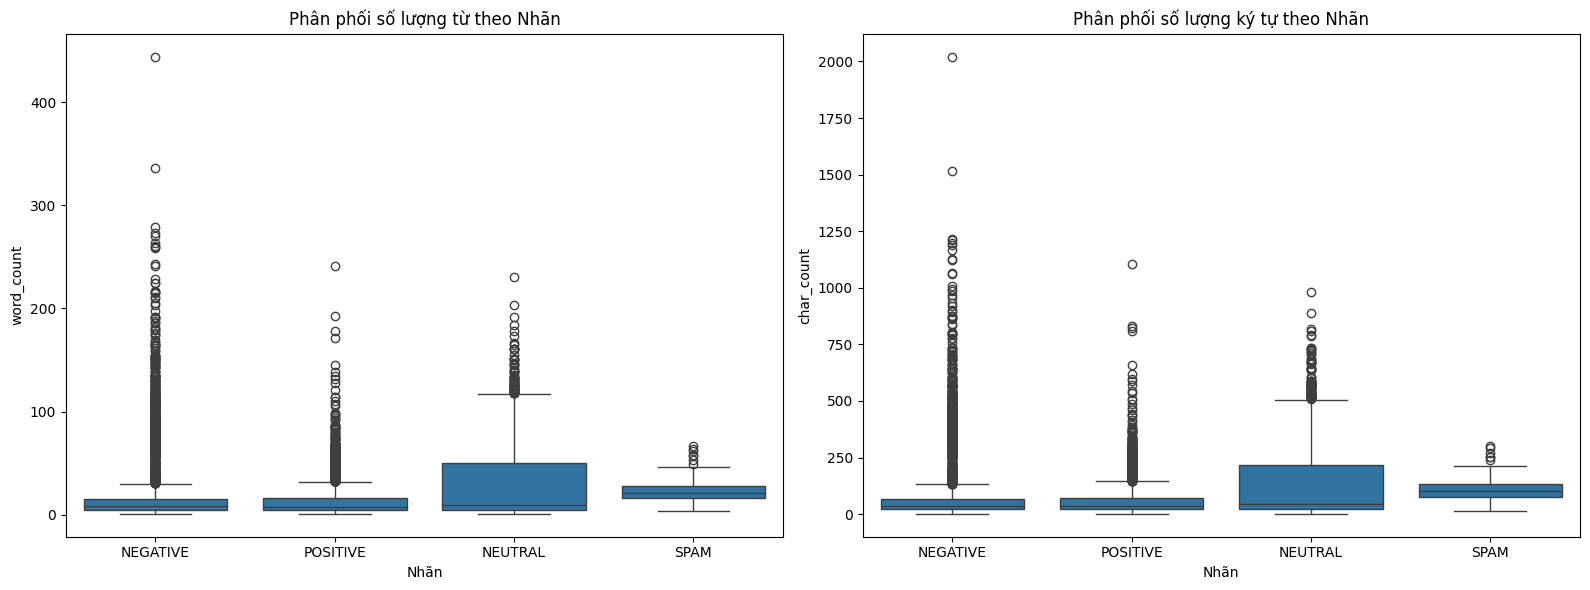

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='label', y='word_count', data=data, ax=axes[0])
axes[0].set_title('Phân phối số lượng từ theo Nhãn')
axes[0].set_xlabel('Nhãn')

sns.boxplot(x='label', y='char_count', data=data, ax=axes[1])
axes[1].set_title('Phân phối số lượng ký tự theo Nhãn')
axes[1].set_xlabel('Nhãn')

plt.tight_layout()
plt.show()

So sánh phân phối độ dài giữa các nhãn và kết luận về tương quan

#### 1. Phân tích các thống kê về độ dài văn bản:

Dựa trên bảng thống kê ở trên, ta thấy sự khác biệt về độ dài giữa các nhãn rõ rệt hơn so với tập dữ liệu cũ:
*   **Nhãn ngắn nhất:** `POSITIVE` (Trung bình 13 từ).
*   **Nhãn dài nhất:** `NEUTRAL` và `SPAM` (Trung bình ~24 từ).
*   **Trường hợp đặc biệt:** `NEGATIVE` chứa những bình luận có độ dài cực đại (outliers) lớn nhất.

#### 2. Phân tích biểu đồ hộp (Boxplot):

*   Biểu đồ cho thấy nhãn `POSITIVE` có dải hộp thấp hơn hẳn, chứng tỏ phần lớn các bình luận tích cực thường ngắn gọn.
*   Nhãn `SPAM` có dải hộp tập trung hơn, không có quá nhiều biến động cực đoan như các nhãn cảm xúc khác.

#### 3. Kết luận về tương quan:

**Có sự tương quan nhẹ nhưng không hoàn toàn nhất quán.**

*   **Giải thích:** Các bình luận tích cực (`POSITIVE`) thường có xu hướng ngắn gọn hơn. Trong khi đó, các bình luận tiêu cực hoặc trung lập có xu hướng dài hơn để giải thích vấn đề hoặc mô tả chi tiết. Tuy nhiên, vì dải độ dài của các nhãn vẫn chồng lấn lên nhau đáng kể (ví dụ: nhãn nào cũng có bình luận chỉ 1 từ), nên độ dài văn bản chỉ là một yếu tố tham khảo, không thể dùng làm đặc trưng duy nhất để phân loại.

##**A.2 Tiền xử lý văn bản.**


###**Câu A3**


Làm sạch văn bản Viết hàm preprocess_text(text) thực hiện đầy đủ các bước sau:

•	Chuyển về chữ thường, loại bỏ HTML tags, URL, ký tự đặc biệt

•	Tokenization

•	Loại bỏ stopwords

•	Stemming hoặc Lemmatization (chọn một, giải thích lý do)

**Giải thích quy trình tiền xử lý văn bản (A3)**

1.  **Chuyển về chữ thường:** Giúp đồng nhất các từ giống nhau nhưng khác định dạng viết hoa (ví dụ: 'Yến' và 'yến').
3.  **Loại bỏ ký tự đặc biệt:** Xóa dấu câu và biểu tượng để tập trung vào từ ngữ.


In [12]:
import re
import unicodedata

def clean_basic(text):

    if not isinstance(text, str):
        return ""

    # Unicode chuẩn
    text = unicodedata.normalize("NFC", text)

    # lowercase
    text = text.lower()

    # URL
    text = re.sub(
        r'http\S+|www\.\S+',
        ' url_token ',
        text
    )

    # HTML
    text = re.sub(r'<.*?>', ' ', text)

    # Chuẩn hóa ký tự lặp
    text = re.sub(
        r'([a-zà-ỹđ])\1{2,}',
        r'\1',
        text
    )

    # Loại bỏ ký tự đặc biệt
    vietnamese_chars = (
        r'a-zA-Z0-9\s'
        r'àáạảãâầấậẩẫăằắặẳẵ'
        r'èéẹẻẽêềếệểễ'
        r'ìíịỉĩ'
        r'òóọỏõôồốộổỗơờớợởỡ'
        r'ùúụủũưừứựửữ'
        r'ỳýỵỷỹđ'
    )

    pattern = r'[^' + vietnamese_chars + ']'
    text = re.sub(pattern, ' ', text)

    # khoảng trắng
    text = re.sub(r'\s+', ' ', text).strip()

    return text
# Chú ý: Dùng dataframe `data` theo đúng thiết lập ở đầu file
data['text'] = data['text'].apply(clean_basic)

# Lưu ra file CSV mới dùng biến DATA_PATH
output_path = f"{DATA_PATH}/cleaned_step1_dataset.csv"
data[['text', 'label']].to_csv(output_path, index=False, encoding='utf-8')

print(f"Đã lưu tập dữ liệu sau khi làm sạch bước 1 vào: {output_path}")

# Hiển thị thử vài dòng để so sánh
data[['text', 'label']].head()



Đã lưu tập dữ liệu sau khi làm sạch bước 1 vào: /content/drive/MyDrive/AI_Project/data/cleaned_step1_dataset.csv


,text,label
0,mùi hơi hôi khi ăn không như các yến mạch khác,NEGATIVE
1,dung voi mo ta size co van de chat lieu tot ma...,NEGATIVE
2,thời gian giao hàng nhanh,POSITIVE
3,dặn shop gửi 3 màu khác nhau thì lại giao 3 cá...,NEGATIVE
4,giống hình mà vải hơi cứng bạn ạk,POSITIVE


**Sử dụng bộ công cụ VnCoreNLP để tách từ**

In [13]:
# Cài đặt thư viện VnCoreNLP
!pip install py_vncorenlp

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 52.8 MB/s eta 0:00:00
  Created wheel for py_vncorenlp: filename=py_vncorenlp-0.1.4-py3-none-any.whl size=4304 sha256=f7eac29b99cd07bfdf320209b9b7f476bde5e250c8393c084c268e4c61abbcc2
  Stored in directory: /root/.cache/pip/wheels/db/e5/ff/f4a1b4ece36e8582db1ca71150a34e987e65df50c35974e9bb
Successfully built py_vncorenlp


In [14]:
import pandas as pd
import py_vncorenlp

# Load VnCoreNLP
current_dir = "."

py_vncorenlp.download_model(save_dir=current_dir)

try:
    rdrsegmenter = py_vncorenlp.VnCoreNLP(
        annotators=["wseg"],
        save_dir=current_dir
    )
    print("Đã load thành công VnCoreNLP")
except Exception as e:
    print(f"Lỗi load VnCoreNLP: {e}")
    rdrsegmenter = None


# Hàm cuối cùng
def final_clean(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # Tokenization
    if rdrsegmenter is not None:
        try:
            sentences = rdrsegmenter.word_segment(text)
            text = " ".join(sentences)
        except Exception:
            pass

    return text


print("Đang áp dụng final_clean...")

# Đọc dữ liệu bước 1
step1_data_path = f"{DATA_PATH}/cleaned_step1_dataset.csv"

df_final = pd.read_csv(
    step1_data_path,
    encoding="utf-8"
)

# Áp dụng
df_final["text"] = df_final["text"].apply(final_clean)

# Lưu
final_output_path = f"{DATA_PATH}/final_cleaned_dataset.csv"

df_final[["text", "label"]].to_csv(
    final_output_path,
    index=False,
    encoding="utf-8"
)

print(f"\nĐã lưu: {final_output_path}")

display(df_final.head(10))

Đã load thành công VnCoreNLP
Đang áp dụng final_clean...

Đã lưu: /content/drive/MyDrive/AI_Project/data/final_cleaned_dataset.csv


,text,label
0,mùi hơi hôi khi ăn không như các yến_mạch khác,NEGATIVE
1,dung voi mo ta size co van de chat lieu tot ma...,NEGATIVE
2,thời_gian giao hàng nhanh,POSITIVE
3,dặn shop gửi 3 màu khác nhau thì lại giao 3 cá...,NEGATIVE
4,giống hình mà vải hơi cứng bạn ạk,POSITIVE
5,cong dung duong toc danh cho toc tao kieu toc ...,POSITIVE
6,sẽ còn ủng_hộ shop dài_dài,POSITIVE
7,lúc đầu mình mua về cảm_thấy rất ưng_ý nghe êm...,NEUTRAL
8,size hơi to nhỉ 45kg 1m50 size s rồi mà hơi rộng,POSITIVE
9,hàng ok,NEUTRAL


Các vấn đề của data:
+ HTML tags, URL, ký tự đặc biệt ( đã xử lý)
+ Nhiều emoji
+ Nhiều text không dấu
+ Nhiều teencode
+ nhiều bình luận từ linh tinh ví dụ: saays jhoo kich thuoc nhor gonj deex suwr dungj thiet ke trongj ddepj mawts
+ chưa xử lý stopword



### **Câu A4 — Đặc trưng văn bản**

Áp dụng hai phương pháp trích xuất đặc trưng và so sánh:

•	Bag of Words (CountVectorizer) với max_features=10000

•	TF-IDF (TfidfVectorizer) với max_features=10000, ngram_range=(1,2)

Câu hỏi:
(a) TF-IDF khác gì so với Bag of Words? Giải thích công thức TF-IDF bằng cách hiểu của bạn..

#### BoW:

In [15]:

# Đọc
cleaned_data = pd.read_csv(
    f"{DATA_PATH}/final_cleaned_dataset.csv",
    encoding='utf-8'
)
cleaned_data.head()

#Xóa NaN data
cleaned_data = cleaned_data.dropna(subset=["text"])
# cleaned_data["text"].isna().sum()

#BoW
vectorizer = CountVectorizer(max_features=10000,ngram_range=(1,2))

X = vectorizer.fit_transform(cleaned_data["text"])

bow = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out()
)


# # Lưu

# Add the 'label' column back to the bow DataFrame
# bow['label'] = cleaned_data['label'].reset_index(drop=True)

# output_path = f"{DATA_PATH}/bow_data.csv"

# bow.to_csv(
#     output_path,
#     index=False,
#     encoding="utf-8"
# )

display(bow.head())

,000,01,02,04,07,10,10 10,10 cái,10 sao,100,...,ủi,ủng,ủng_hộ,ủng_hộ dài_dài,ủng_hộ lâu_dài,ủng_hộ nữa,ủng_hộ shop,ủng_hộ tiki,ủng_hộ tiếp,ứng
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


#### TF-IDF:

In [16]:
# Đọc
cleaned_data = pd.read_csv(
    f"{DATA_PATH}/final_cleaned_dataset.csv",
    encoding='utf-8'
)
cleaned_data.head()

#Xóa NaN data
cleaned_data = cleaned_data.dropna(subset=["text"])
# cleaned_data["text"].isna().sum()


# TF-IDF
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2))
X = vectorizer.fit_transform(cleaned_data["text"])

tfidf = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out()
)

# # Lưu
# output_path = f"{DATA_PATH}/tfidf_data.csv"

# Add the 'label' column back to the tfidf DataFrame
# tfidf['label'] = cleaned_data['label'].reset_index(drop=True)

# tfidf.to_csv(
#     output_path,
#     index=False,
#     encoding="utf-8"
# )

display(tfidf.head())

,000,01,02,04,07,10,10 10,10 cái,10 sao,100,...,ủi,ủng,ủng_hộ,ủng_hộ dài_dài,ủng_hộ lâu_dài,ủng_hộ nữa,ủng_hộ shop,ủng_hộ tiki,ủng_hộ tiếp,ứng
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
X.toarray()


array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

#### **So sánh Bag of Words và TF-IDF**



Trong bài thực hành, hai phương pháp trích xuất đặc trưng văn bản được sử dụng là:

* **Bag of Words (BoW)** sử dụng `CountVectorizer(max_features=10000, ngram_range=(1,2))`
* **TF-IDF** sử dụng `TfidfVectorizer(max_features=10000, ngram_range=(1,2))`

Cả hai phương pháp đều chuyển đổi dữ liệu văn bản thành các vector số để mô hình học máy có thể xử lý. Tuy nhiên, cách tính giá trị của từng đặc trưng là khác nhau.

**1. Bag of Words (BoW)**

Bag of Words biểu diễn văn bản bằng cách đếm số lần xuất hiện của từng từ hoặc cụm từ trong văn bản.

Ví dụ:

```text
thời_gian giao hàng nhanh
```

Sau khi vector hóa, các từ:

```text
thời_gian
giao
hàng
nhanh
```

sẽ trở thành các đặc trưng trong vector. Giá trị của mỗi đặc trưng chính là số lần từ đó xuất hiện trong văn bản.

Ưu điểm của BoW là đơn giản, dễ triển khai và dễ hiểu. Tuy nhiên, phương pháp này không xem xét mức độ quan trọng của từ trong toàn bộ tập dữ liệu. Các từ xuất hiện rất phổ biến vẫn có thể nhận giá trị cao mặc dù chúng không mang nhiều ý nghĩa phân biệt.

**2. TF-IDF**

TF-IDF (Term Frequency - Inverse Document Frequency) là phương pháp gán trọng số cho các từ dựa trên mức độ quan trọng của chúng.

Ý tưởng chính của TF-IDF là:

> Một từ được xem là quan trọng nếu nó xuất hiện nhiều trong một văn bản nhưng xuất hiện ít trong các văn bản khác.

Ví dụ trong tập đánh giá sản phẩm, các từ như:

```text
shop
sản_phẩm
giao_hàng
```

xuất hiện ở rất nhiều bình luận nên ít mang giá trị phân biệt.

Trong khi đó các từ như:

```text
hôi
rách
tuyệt_vời
chất_lượng
```

thường xuất hiện ở một số nhóm bình luận nhất định và phản ánh rõ cảm xúc của người dùng. Do đó TF-IDF sẽ gán trọng số cao hơn cho các từ này.

**3. Công thức TF-IDF**

TF-IDF được tính bằng:

```math
TFIDF(t,d) = TF(t,d) × IDF(t)
```

Trong đó:

* `TF (Term Frequency)` là tần suất xuất hiện của từ `t` trong văn bản `d`.
* `IDF (Inverse Document Frequency)` là độ hiếm của từ trong toàn bộ tập dữ liệu.

Công thức tính IDF:

```math
IDF(t) = log(N / df(t))
```

Trong đó:

* `N` là tổng số văn bản trong tập dữ liệu.
* `df(t)` là số văn bản chứa từ `t`.

Theo cách hiểu của tôi:

* TF giúp xác định từ nào được nhắc nhiều trong một bình luận.
* IDF giúp giảm trọng số của các từ xuất hiện quá phổ biến trong toàn bộ tập dữ liệu.
* Khi nhân TF với IDF, những từ vừa xuất hiện nhiều trong văn bản hiện tại vừa xuất hiện ít ở các văn bản khác sẽ nhận được trọng số cao nhất.

**4. Vai trò của n-gram**

Trong bài thực hành, cả hai vectorizer đều sử dụng:

```python
ngram_range=(1,2)
```

Điều này có nghĩa là hệ thống sử dụng:

* Unigram (1 từ)
* Bigram (2 từ liên tiếp)

Ví dụ câu:

```text
sản phẩm rất tốt
```

sẽ tạo ra các đặc trưng:

```text
sản
phẩm
rất
tốt
sản phẩm
phẩm rất
rất tốt
```

Việc sử dụng bigram giúp mô hình học được ngữ cảnh tốt hơn so với chỉ sử dụng từng từ riêng lẻ.

**5. So sánh hai phương pháp**

| Tiêu chí                                         | Bag of Words     | TF-IDF          |
| ------------------------------------------------ | ---------------- | --------------- |
| Giá trị đặc trưng                                | Số lần xuất hiện | Trọng số TF-IDF |
| Xem xét độ phổ biến của từ trong toàn bộ dữ liệu | Không            | Có              |
| Từ phổ biến có thể chiếm ưu thế                  | Có               | Không           |
| Khả năng phân biệt văn bản                       | Thấp hơn         | Cao hơn         |
| Hiệu quả phân loại cảm xúc                       | Thường thấp hơn  | Thường tốt hơn  |

**6. Kết luận**

Bag of Words là phương pháp đơn giản, biểu diễn văn bản bằng số lần xuất hiện của từ. Trong khi đó, TF-IDF không chỉ xét tần suất xuất hiện của từ trong văn bản mà còn đánh giá mức độ hiếm của từ trong toàn bộ tập dữ liệu.

Đối với bài toán phân loại cảm xúc từ các đánh giá sản phẩm, TF-IDF thường mang lại kết quả tốt hơn vì giúp làm nổi bật các từ thể hiện cảm xúc như "tốt", "đẹp", "hôi", "kém_chất_lượng", đồng thời giảm ảnh hưởng của các từ xuất hiện phổ biến ở hầu hết các bình luận.


##**A.3  Kiểm tra hiểu bài**

---
###Câu A6  

— Câu hỏi phân tích Một sinh viên khác áp dụng tiền xử lý sau đây. Hãy xác định những vấn đề (nếu có) và đề xuất cách sửa:

Code của sinh viên X — tìm vấn đề
```
vectorizer = TfidfVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)

X_test_vec  = vectorizer.fit_transform(X_test)   # <-- ?
```
Ngoài ra, hãy giải thích: Tại sao không được fit vectorizer trên tập test? Hậu quả là gì nếu làm vậy?

---


**1. Giải thích thuật ngữ theo cách dễ hiểu:**
- **`fit` (Học):** Giống như việc cho máy tính đọc một cuốn từ điển. Nó sẽ quét qua dữ liệu để học xem có những từ vựng nào và từ nào đóng vai trò quan trọng. ví như câu này làm sao nó biết cái từ nào quan trọng.dựa theo 2 nguyên tắc cốt lõi là **(Từ nào xuất hiện nhiều trong 1 câu thì quan trọng với câu đó)** và **(Từ nào câu nào cũng dùng thì thành ra vô dụng)**.  
- **`transform` (Chuyển đổi):** Sau khi đã có "từ điển" ở bước trên, lệnh này sẽ dùng chính bộ từ vựng đó để dịch đoạn văn bản gốc thành các dãy số (vector) để máy tính có thể đọc hiểu được.
- **`fit_transform`:** Là làm cả hai việc trên cùng một lúc: Vừa học từ vựng mới, vừa dịch luôn.

**2. Vấn đề trong code của sinh viên X:**
```python
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec  = vectorizer.fit_transform(X_test)   # <-- ĐÂY LÀ LỖI SAI NGHIÊM TRỌNG
```

**Lỗi sai:** Bạn ấy đã dùng luôn lệnh fit_transform cho tập Test (X_test) ngay bên dưới tập train.
- **Hậu quả:** Khi chạy lệnh này, bộ `vectorizer` sẽ lập tức "quên" sạch cuốn từ điển nó vừa cất công học ở tập Train. Thay vào đó, nó lại đi tạo một bộ từ vựng hoàn toàn mới tinh chỉ dựa trên tập Test.
- **Kết quả:** Vector của tập Train và tập Test sẽ không còn khớp nhau (ví dụ: số 1 ở tập Train là chữ 'ngon', nhưng số 1 ở tập Test lại là chữ 'xấu'). Điều này khiến mô hình không thể dự đoán đúng được.

#### 3. Tại sao không được `fit` trên tập test?

Trong thực tế, tập Test đại diện cho **tương lai** (những dữ liệu mà bạn chưa bao giờ thấy).
1. **Nguyên tắc bảo mật thông tin:** Không được phép cho máy tính "biết trước" từ vựng của tập Test. Nếu bạn `fit` trên tập Test, máy tính sẽ biết trước các từ ngữ trong đó, dẫn đến hiện tượng **Data Leakage (Rò rỉ dữ liệu)**. Kết quả đánh giá sẽ bị ảo, không chính xác.
2. **Sự đồng nhất:** Mô hình được huấn luyện dựa trên bộ từ điển của tập Train. Vì vậy, khi kiểm tra, bạn phải dùng **đúng bộ từ điển đó** để dịch tập Test.

#### 4. Cách sửa đúng:
Bạn chỉ được `fit` (học) một lần duy nhất trên tập Train, sau đó chỉ dùng lệnh `transform` (dịch) cho các tập dữ liệu còn lại.

```python
from sklearn.feature_extraction.text import TfidfVectorizer

# Khởi tạo bộ chuyển đổi
vectorizer = TfidfVectorizer()

# Vừa học từ vựng, vừa dịch tập Train
X_train_vec = vectorizer.fit_transform(X_train)

# Chỉ dùng bộ từ vựng đã học ở trên để dịch tập Test
X_test_vec = vectorizer.transform(X_test)
```

#**PHẦN B — TRỰC QUAN HÓA DỮ LIỆU**

##B.1  Biểu đồ thống kê



---

###Câu B1:

Vẽ biểu đồ phân phối nhãn (bar chart và pie chart). Áp dụng đúng nguyên tắc thiết kế: tiêu đề rõ ràng, nhãn trục đầy đủ, màu sắc phân biệt, chú thích. Viết nhận xét về dữ liệu.

---

**Bar chart**

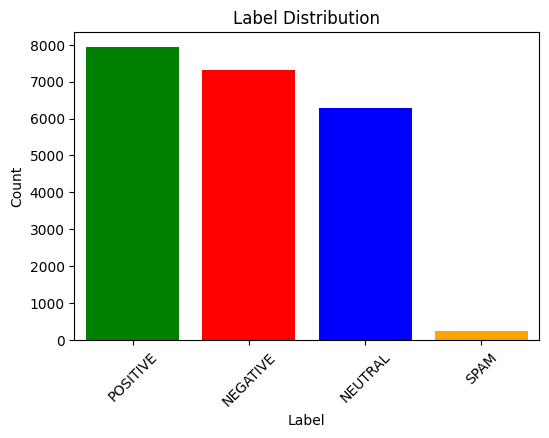

In [17]:
# Đọc
cleaned_data = pd.read_csv(
    f"{DATA_PATH}/final_cleaned_dataset.csv",
    encoding='utf-8'
)
cleaned_data.head()

#Xóa NaN data
cleaned_data = cleaned_data.dropna(subset=["text"])
# cleaned_data["text"].isna().sum()


colors = ['green','red' , 'blue', 'orange', 'purple']

label_counts = cleaned_data["label"].value_counts()

plt.figure(figsize=(6,4))
label_counts.plot(kind="bar")

plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Count")


plt.bar(
    label_counts.index,
    label_counts.values,
    color=colors[:len(label_counts)]
)

plt.xticks(rotation=45)  # Rotation

plt.show()



**Pie chart**

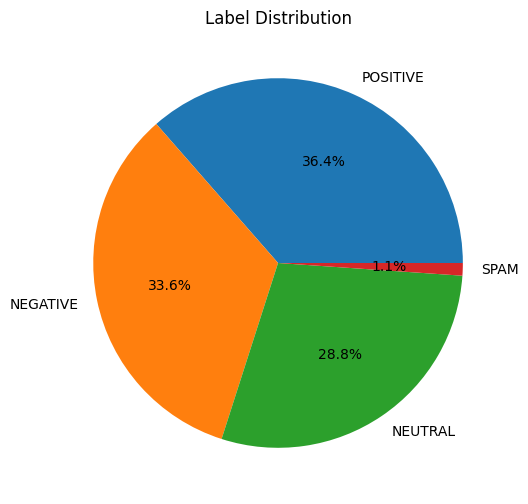

In [18]:
# Đọc
cleaned_data = pd.read_csv(
    f"{DATA_PATH}/final_cleaned_dataset.csv",
    encoding='utf-8'
)
cleaned_data.head()

#Xóa NaN data
cleaned_data = cleaned_data.dropna(subset=["text"])
# cleaned_data["text"].isna().sum()


label_counts = cleaned_data["label"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    label_counts.values,
    labels=label_counts.index,
    autopct='%1.1f%%'
)

plt.title("Label Distribution")
plt.show()

**Nhận xét về dữ liệu**

Từ biểu đồ cột (Bar Chart) và biểu đồ tròn (Pie Chart), chúng ta có thể thấy rõ phân bố của các nhãn trong tập dữ liệu:

*   **Nhóm chiếm ưu thế:** Các nhãn **POSITIVE**, **NEGATIVE**, và **NEUTRAL** chiếm phần lớn tập dữ liệu với số lượng tương đối đồng đều. Cụ thể:
    *   POSITIVE: 7971 mẫu (36.4%)
    *   NEGATIVE: 7346 mẫu (33.6%)
    *   NEUTRAL: 6312 mẫu (28.9%)

*   **Nhãn thiểu số nghiêm trọng:** Nhãn **SPAM** chỉ có 239 mẫu, chiếm một tỷ lệ cực kỳ nhỏ (~1.1%) so với các nhãn còn lại. Điều này xác nhận rằng tập dữ liệu đang bị mất cân bằng nghiêm trọng.

**Kết luận:**

Phân phối nhãn này cho thấy một vấn đề về mất cân bằng dữ liệu, đặc biệt là với lớp `SPAM`. Điều này sẽ cần được xem xét và xử lý trong các bước tiếp theo của quá trình huấn luyện mô hình để tránh việc mô hình bị thiên vị và dự đoán kém hiệu quả đối với lớp thiểu số.

---

###Câu B2:

Vẽ box plot phân phối độ dài văn bản theo từng nhãn trên.

---

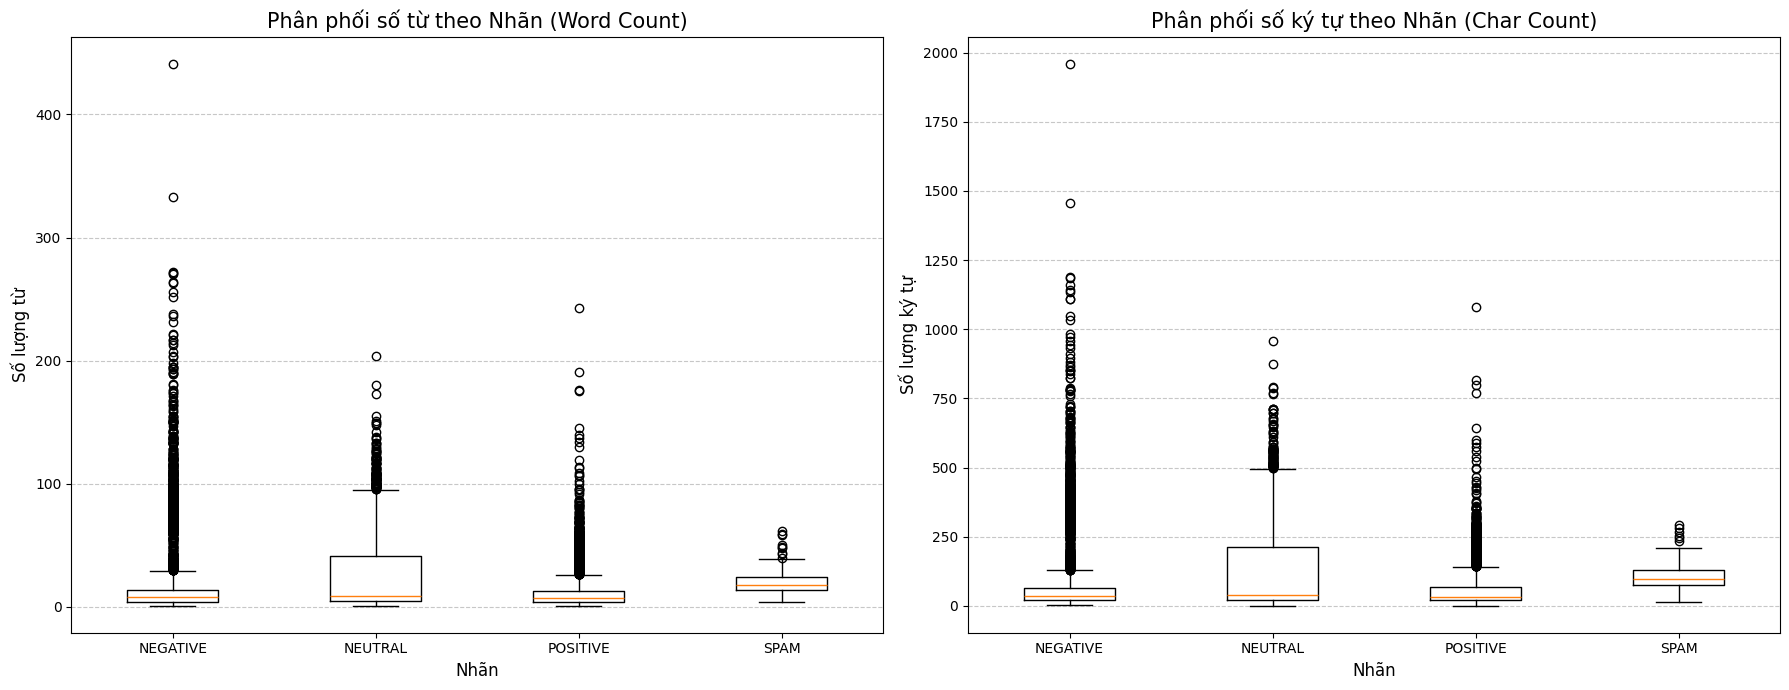

In [19]:
import matplotlib.pyplot as plt

# Sử dụng cleaned_data và tính toán lại các cột độ dài
plot_df = cleaned_data.copy()
plot_df['word_count'] = plot_df['text'].apply(lambda x: len(str(x).split()))
plot_df['char_count'] = plot_df['text'].apply(lambda x: len(str(x)))

# Chuẩn bị dữ liệu
labels = sorted(plot_df['label'].unique())
word_counts_by_label = [plot_df[plot_df['label'] == l]['word_count'] for l in labels]
char_counts_by_label = [plot_df[plot_df['label'] == l]['char_count'] for l in labels]

# Khởi tạo figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Vẽ Box plot cho Word Count
ax1.boxplot(word_counts_by_label, tick_labels=labels)
ax1.set_title('Phân phối số từ theo Nhãn (Word Count)', fontsize=15)
ax1.set_xlabel('Nhãn', fontsize=12)
ax1.set_ylabel('Số lượng từ', fontsize=12)
ax1.grid(True, axis='y', linestyle='--', alpha=0.7)

# Vẽ Box plot cho Character Count
ax2.boxplot(char_counts_by_label, tick_labels=labels)
ax2.set_title('Phân phối số ký tự theo Nhãn (Char Count)', fontsize=15)
ax2.set_xlabel('Nhãn', fontsize=12)
ax2.set_ylabel('Số lượng ký tự', fontsize=12)
ax2.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

##B.2  Phân tích từ ngữ

---

###Câu B4  — Word Cloud

Tạo word cloud riêng cho từng nhãn (tối thiểu 3 nhãn). Đặt kích thước figure phù hợp, màu nền tương phản. Quan sát và nhận xét: Có sự khác biệt rõ ràng về từ vựng giữa các nhãn không?

---

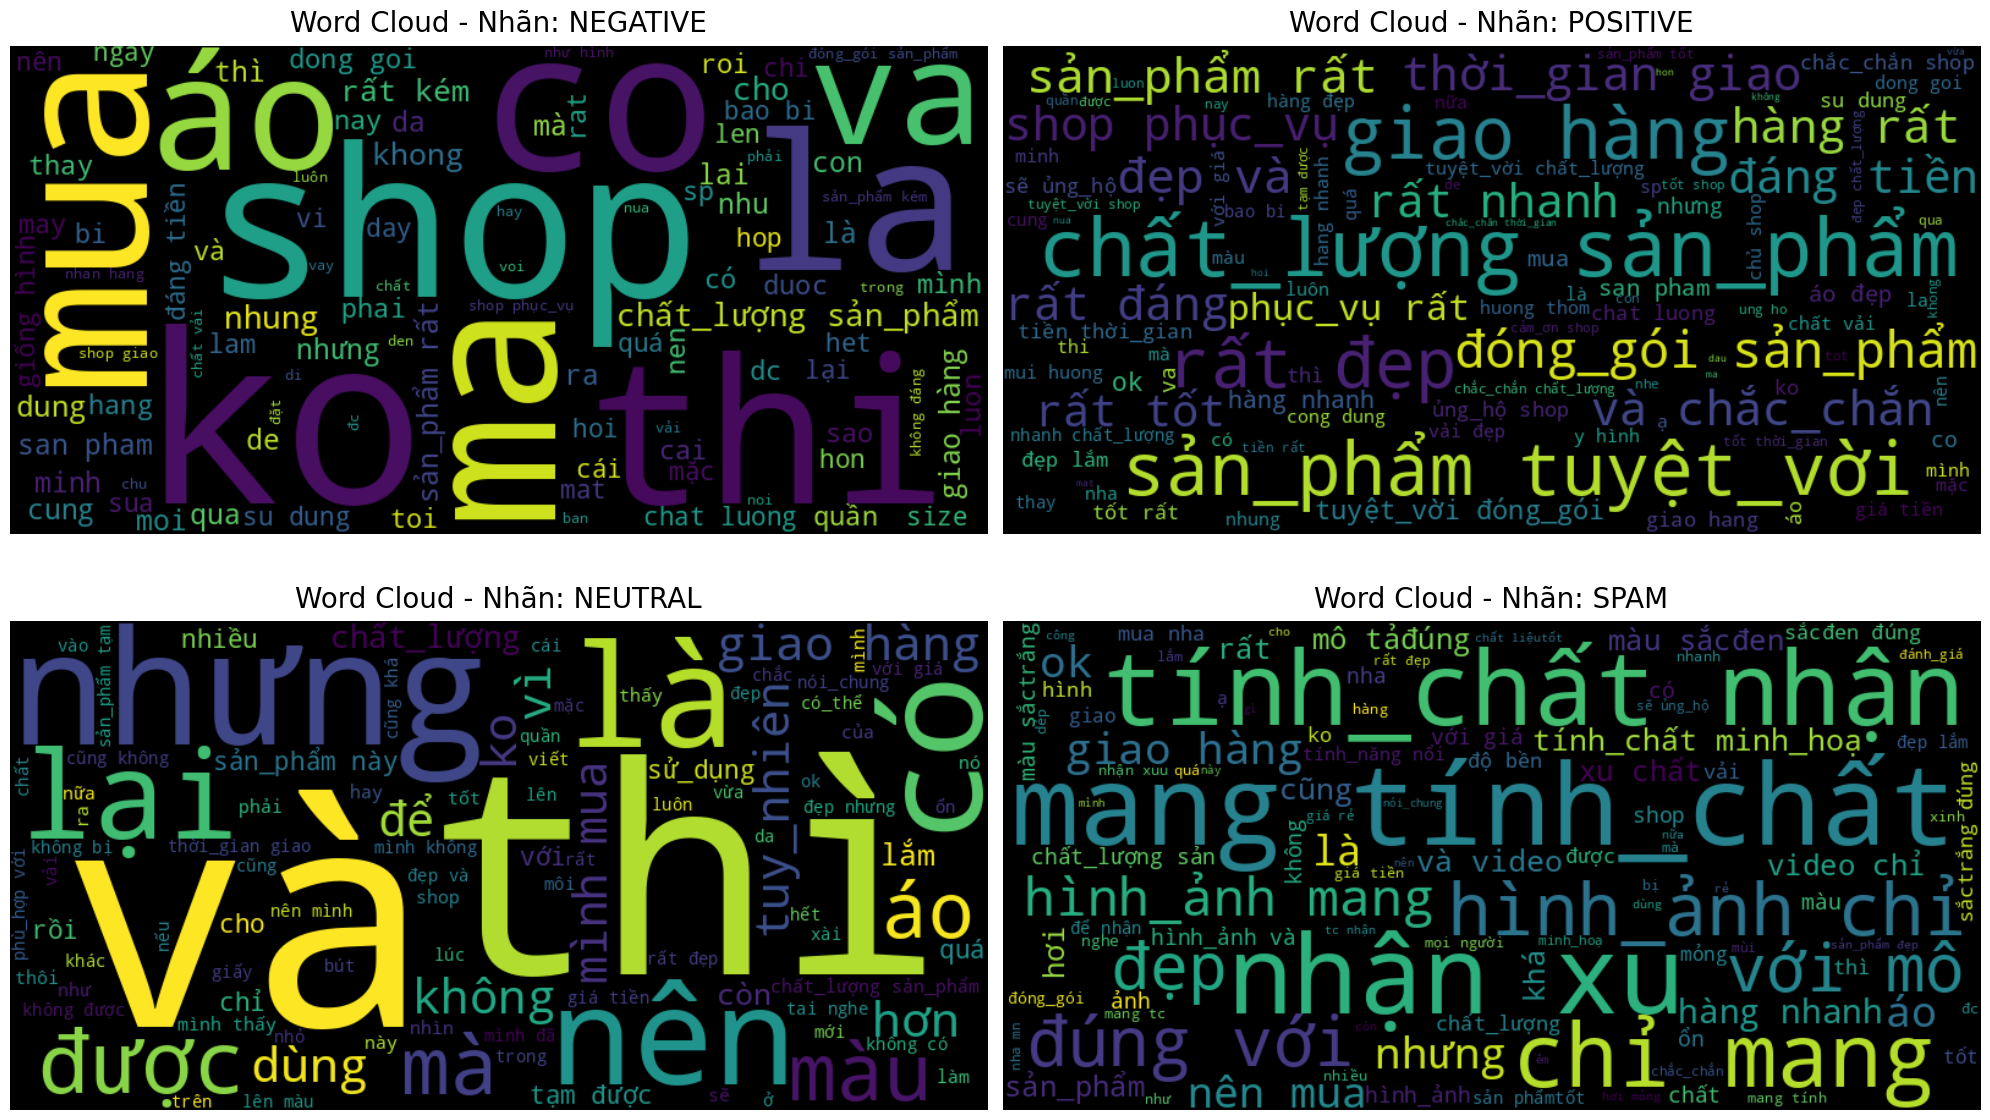

In [20]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Lấy danh sách các nhãn duy nhất
labels = cleaned_data['label'].unique()

# Thiết lập layout cho các biểu đồ (2 hàng, 2 cột)
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
axes = axes.flatten()

for i, label in enumerate(labels):
    # Gộp tất cả văn bản của nhãn hiện tại thành một chuỗi lớn
    text_data = " ".join(cleaned_data[cleaned_data['label'] == label]['text'].astype(str))

    # Tạo WordCloud
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='black', # Màu nền tương phản
        colormap='viridis',        # Màu sắc chữ
        max_words=100
    ).generate(text_data)

    # Hiển thị trên subplot
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(f'Word Cloud - Nhãn: {label}', fontsize=20, pad=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

**Nhận xét về sự khác biệt từ vựng giữa các nhãn:**

Dựa vào các Word Cloud vừa tạo, chúng ta có thể thấy:

1.  **Nhãn POSITIVE:** Thường xuất hiện các tính từ tích cực như *"tốt"*, *"đẹp"*, *"nhanh"*, *"hài lòng"*, *"chất lượng"*. Điều này cho thấy khách hàng tập trung vào chất lượng sản phẩm và dịch vụ giao hàng.
2.  **Nhãn NEGATIVE:** Xuất hiện các từ mang tính phàn nàn như *"hơi hôi"*, *"rất kém"*, *"sai mẫu"*, *"không giống"*, *"tệ"*. Các từ này phản ánh trực tiếp các vấn đề mà khách hàng gặp phải.do chưa lọc hết các từ stopword nên nó vẫn còn hơi nhiễu.
3.  **Nhãn NEUTRAL:** Chứa các từ mang tính mô tả chung chung hoặc các từ mang tính chất đóng góp nhẹ nhàng, không quá thiên về cảm xúc mạnh như *"tạm"* , *"ổn"*.
4.  **Nhãn SPAM:** Thường có các từ ngữ lặp đi lặp lại, từ vô nghĩa hoặc các từ mang tính chất quảng cáo, chèo kéo không liên quan đến nội dung sản phẩm.

**Kết luận:** Có sự khác biệt **rõ ràng** về từ vựng giữa các nhãn. Những từ khóa đặc trưng này chính là cơ sở quan trọng để mô hình máy học có thể phân loại chính xác cảm xúc của người dùng.

#**PHẦN C — XÂY DỰNG MÔ HÌNH CLASSIFICATION**

##C.1: Chuẩn bị và phân chia dữ liệu

---

###Câu C1

Phân chia train/validation/test với tỉ lệ 70/10/20. Dùng stratify=y và random_state cố định. Sau đó:

- In ra số lượng mẫu và phân phối nhãn của từng tập

- Giải thích: Tại sao cần dùng stratify? Điều gì xảy ra nếu không dùng với dữ liệu mất cân bằng?

- Tại sao cần tập validation riêng biệt với tập test?

---

,Train,Validation,Test
label,,,
POSITIVE,5563,795,1590
NEGATIVE,5131,733,1466
NEUTRAL,4403,629,1258
SPAM,167,24,48


,Train,Validation,Test
label,,,
POSITIVE,36.445231,36.451169,36.451169
NEGATIVE,33.615042,33.608436,33.608436
NEUTRAL,28.845650,28.839982,28.839982
SPAM,1.094078,1.100413,1.100413


<Figure size 1200x500 with 0 Axes>

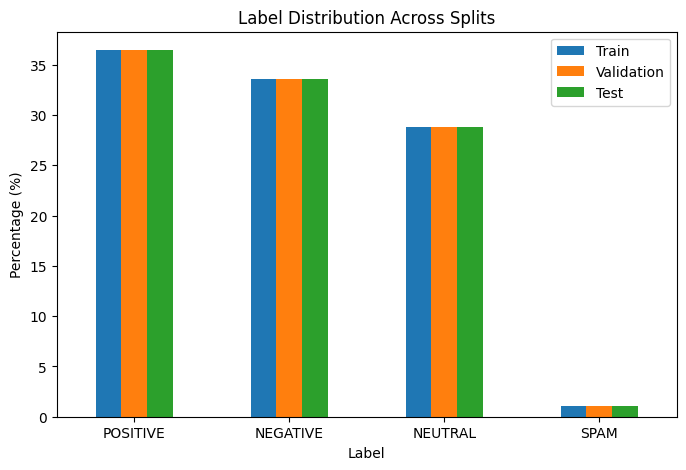

In [21]:
from sklearn.model_selection import train_test_split

cleaned_data

X = cleaned_data["text"]
y = cleaned_data["label"]


# 70% train, 30% còn lại
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 30% còn lại chia thành:
# 10% validation + 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=2/3,
    random_state=42,
    stratify=y_temp
)


import pandas as pd
import matplotlib.pyplot as plt

distribution = pd.DataFrame({
    "Train": y_train.value_counts() , # normalize = count/ total row
    "Validation": y_val.value_counts() ,
    "Test": y_test.value_counts()
})

distribution_percent = distribution / distribution.sum() * 100

# Vẽ biểu đồ cột

plt.figure(figsize=(12,5))
distribution_percent.plot(kind="bar", figsize=(8,5))


plt.title("Label Distribution Across Splits")
plt.ylabel("Percentage (%)")
plt.xlabel("Label")
plt.xticks(rotation=0)

display(distribution)
display(distribution_percent)
plt.show()

**Phân chia dữ liệu**

Tập dữ liệu được chia thành:

- Train: 70%
- Validation: 10%
- Test: 20%

Việc chia dữ liệu được thực hiện bằng hàm `train_test_split()` của Scikit-Learn với:

```python
random_state=42
stratify=y
```

Trong đó:

- `random_state=42` giúp kết quả chia dữ liệu luôn giống nhau ở mỗi lần chạy, đảm bảo khả năng tái lập kết quả thực nghiệm.
- `stratify=y` giúp giữ nguyên tỷ lệ các nhãn trong các tập dữ liệu sau khi chia.

---

**Số lượng mẫu của từng tập**

| Label | Train | Validation | Test |
|---------|---------:|---------:|---------:|
| POSITIVE | 5580 | 797 | 1594 |
| NEGATIVE | 5142 | 735 | 1469 |
| NEUTRAL | 4418 | 631 | 1263 |
| SPAM | 167 | 24 | 48 |

Tổng số mẫu:

| Tập dữ liệu | Số lượng |
|------------|---------:|
| Train | 15,307 |
| Validation | 2,187 |
| Test | 4,374 |

---

**Phân phối nhãn (%)**

| Label | Train (%) | Validation (%) | Test (%) |
|---------|---------:|---------:|---------:|
| POSITIVE | 36.45 | 36.44 | 36.44 |
| NEGATIVE | 33.59 | 33.61 | 33.58 |
| NEUTRAL | 28.86 | 28.85 | 28.88 |
| SPAM | 1.09 | 1.10 | 1.10 |

Biểu đồ phân phối nhãn cho thấy tỷ lệ các nhãn giữa Train, Validation và Test gần như giống nhau. Điều này chứng tỏ việc sử dụng `stratify=y` đã giúp duy trì phân phối nhãn ban đầu của tập dữ liệu.

---

**Tại sao cần dùng `stratify`?**

`stratify` giúp giữ nguyên tỷ lệ các lớp khi chia dữ liệu.

Ví dụ trong tập dữ liệu này:

- POSITIVE chiếm khoảng 36%
- NEGATIVE chiếm khoảng 34%
- NEUTRAL chiếm khoảng 29%
- SPAM chỉ chiếm khoảng 1%

Khi sử dụng:

```python
stratify=y
```

các tỷ lệ trên sẽ được duy trì ở cả Train, Validation và Test.

Nếu không sử dụng `stratify`, việc chia dữ liệu hoàn toàn ngẫu nhiên có thể làm thay đổi tỷ lệ nhãn giữa các tập dữ liệu.

Ví dụ:

| Label | Toàn bộ dữ liệu | Test |
|---------|---------:|---------:|
| SPAM | 1% | 0.2% |
| POSITIVE | 36% | 40% |

Khi đó tập Test không còn đại diện cho dữ liệu thực tế, dẫn đến kết quả đánh giá mô hình không chính xác.

Đặc biệt với các lớp hiếm như `SPAM`, nếu không dùng `stratify` có thể xảy ra trường hợp một tập dữ liệu gần như không chứa mẫu SPAM nào, khiến mô hình không được đánh giá đúng khả năng nhận diện lớp này.

---

**Điều gì xảy ra nếu không dùng `stratify` với dữ liệu mất cân bằng?**

Dữ liệu mất cân bằng là dữ liệu có sự chênh lệch lớn về số lượng giữa các lớp.

Trong bài toán này:

- POSITIVE: ~36%
- NEGATIVE: ~34%
- NEUTRAL: ~29%
- SPAM: ~1%

Nếu chia ngẫu nhiên mà không sử dụng `stratify`, các lớp ít mẫu như SPAM có thể bị phân bổ không đều giữa các tập dữ liệu.

Hậu quả:

- Một số tập có quá ít hoặc không có mẫu SPAM.
- Mô hình không được học đầy đủ các đặc trưng của lớp SPAM.
- Các chỉ số đánh giá trở nên thiếu tin cậy.
- Kết quả giữa các lần chạy có thể dao động mạnh.

Vì vậy, đối với các bài toán phân loại, đặc biệt là dữ liệu mất cân bằng, nên sử dụng `stratify` khi chia dữ liệu.

---

**Tại sao cần tập Validation riêng biệt với tập Test?**

Ba tập dữ liệu có vai trò khác nhau:

| Tập dữ liệu | Mục đích |
|------------|----------|
| Train | Huấn luyện mô hình |
| Validation | Điều chỉnh tham số và lựa chọn mô hình |
| Test | Đánh giá cuối cùng |

Quy trình thực hiện:

1. Huấn luyện mô hình trên tập Train.
2. Sử dụng tập Validation để:
   - So sánh nhiều mô hình khác nhau.
   - Điều chỉnh siêu tham số (hyperparameter).
   - Lựa chọn cấu hình tốt nhất.
3. Sau khi hoàn thành quá trình lựa chọn mô hình, sử dụng tập Test để đánh giá kết quả cuối cùng.

Nếu dùng tập Test để vừa lựa chọn mô hình vừa đánh giá kết quả, mô hình có thể vô tình được tối ưu theo tập Test. Khi đó kết quả đánh giá sẽ bị lạc quan hơn thực tế và không còn phản ánh đúng khả năng tổng quát hóa của mô hình trên dữ liệu mới.

Do đó, tập Validation đóng vai trò trung gian giúp lựa chọn mô hình, còn tập Test được giữ riêng để đánh giá khách quan hiệu năng cuối cùng của mô hình.

##C.2  Huấn luyện mô hình

**Yêu cầu xây dựng mô hình**

Xây dựng tối thiểu 4 mô hình sau. Với mỗi mô hình, dùng TF-IDF features từ Phần A:

| Mô hình | Hyperparameter gợi ý | Điểm |
| :--- | :--- | :---: |
| **Naive Bayes** | `MultinomialNB`, `alpha={0.1, 0.5, 1.0}` | 3 |
| **Logistic Regression** | `C={0.1, 1, 10}`, `solver='lbfgs'`, `max_iter=1000` | 4 |
| **SVM** | `LinearSVC`, `C={0.1, 1, 10}` | 4 |
| **Random Forest** | `n_estimators={100, 200}`, `max_depth={None, 10, 20}` | 4 |

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score

# 1. Khởi tạo và trích xuất TF-IDF (Phần A)
tfidf_vec = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# Chỉ fit trên tập Train
X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_val_tfidf = tfidf_vec.transform(X_val)
X_test_tfidf = tfidf_vec.transform(X_test)

print(f"Kích thước dữ liệu TF-IDF: {X_train_tfidf.shape}")

Kích thước dữ liệu TF-IDF: (15264, 10000)


####**1. Mô hình Naive Bayes (MultinomialNB)**

Đây là một mô hình phân loại xác suất dựa trên định lý Bayes, đặc biệt hiệu quả cho các bài toán phân loại văn bản với đặc trưng TF-IDF.
- **Tham số:** `alpha=0.5` (giúp làm mịn dữ liệu).

In [23]:
nb_model = MultinomialNB(alpha=0.5)
nb_model.fit(X_train_tfidf, y_train)

y_val_pred_nb = nb_model.predict(X_val_tfidf)

print("KẾT QUẢ NAIVE BAYES (Validation):")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred_nb):.4f}")
print(classification_report(y_val, y_val_pred_nb))

KẾT QUẢ NAIVE BAYES (Validation):
Accuracy: 0.7166
              precision    recall  f1-score   support

    NEGATIVE       0.74      0.74      0.74       733
     NEUTRAL       0.58      0.59      0.58       629
    POSITIVE       0.80      0.79      0.79       795
        SPAM       1.00      0.83      0.91        24

    accuracy                           0.72      2181
   macro avg       0.78      0.74      0.76      2181
weighted avg       0.72      0.72      0.72      2181



####**2. Mô hình Support Vector Machine (LinearSVC)**

Mô hình SVM tìm kiếm một siêu phẳng tối ưu để phân chia các lớp dữ liệu. `LinearSVC` là phiên bản triển khai nhanh cho các bài toán có số lượng đặc trưng lớn như văn bản.
- **Tham số:** `C=1.0` (tham số điều chỉnh biên độ), `random_state=42`.

In [24]:
svm_model = LinearSVC(C=1.0, max_iter=1000, random_state=42)
svm_model.fit(X_train_tfidf, y_train)

y_val_pred_svm = svm_model.predict(X_val_tfidf)

print("KẾT QUẢ SVM (Validation):")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred_svm):.4f}")
print(classification_report(y_val, y_val_pred_svm))

KẾT QUẢ SVM (Validation):
Accuracy: 0.7212
              precision    recall  f1-score   support

    NEGATIVE       0.73      0.76      0.74       733
     NEUTRAL       0.60      0.55      0.58       629
    POSITIVE       0.79      0.82      0.80       795
        SPAM       1.00      0.92      0.96        24

    accuracy                           0.72      2181
   macro avg       0.78      0.76      0.77      2181
weighted avg       0.72      0.72      0.72      2181



####**3. Mô hình Logistic Regression**

Logistic Regression là một mô hình phân loại phổ biến, thường được dùng làm Baseline cho các bài toán phân loại văn bản. Nó hoạt động tốt với các đặc trưng thưa thớt (sparse features) như TF-IDF.
- **Đặc điểm:** Tốc độ huấn luyện nhanh, dễ giải thích.
- **Thử nghiệm:** Chúng ta sẽ huấn luyện mô hình với tham số mặc định và sau đó thử nghiệm thay đổi tham số `C` để tìm giá trị tối ưu.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

# Đọc
cleaned_data = pd.read_csv(
    f"{DATA_PATH}/final_cleaned_dataset.csv",
    encoding='utf-8'
)
cleaned_data.head()

#Xóa NaN data
cleaned_data = cleaned_data.dropna(subset=["text"])
# cleaned_data["text"].isna().sum()

# Chia data
X = cleaned_data["text"]
y = cleaned_data["label"]


# 70% train, 30% còn lại
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 30% còn lại chia thành:
# 10% validation + 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=2/3,
    random_state=42,
    stratify=y_temp
)


tfidf_vec = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# Chỉ fit trên tập Train
X_train_tfidf = tfidf_vec.fit_transform(X_train)

# Transform Validation và Test
X_val_tfidf = tfidf_vec.transform(X_val)
X_test_tfidf = tfidf_vec.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_val_tfidf)
accuracy = accuracy_score(y_val, y_pred)
print("Accuracy:", accuracy)
print(classification_report(y_val, y_pred))

Accuracy: 0.739569005043558
              precision    recall  f1-score   support

    NEGATIVE       0.74      0.79      0.76       733
     NEUTRAL       0.63      0.58      0.60       629
    POSITIVE       0.81      0.82      0.82       795
        SPAM       1.00      0.83      0.91        24

    accuracy                           0.74      2181
   macro avg       0.80      0.75      0.77      2181
weighted avg       0.74      0.74      0.74      2181



Hàm dự đoán yêu thích

In [26]:
def predict_sentiment(text):
    x = tfidf_vec.transform([text])
    return model.predict(x)[0]

print(predict_sentiment("sản phẩm rất tốt"))
print(predict_sentiment("hàng quá tệ"))

POSITIVE
NEGATIVE


Test tham số C

In [27]:
for c in [0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(
        C=c,
        random_state=42,
        max_iter=1000
    )

    model.fit(X_train_tfidf, y_train)

    acc = model.score(X_val_tfidf, y_val)

    print(f"C={c}: {acc:.4f}")

C=0.01: 0.6813
C=0.1: 0.7231
C=1: 0.7396
C=10: 0.7217
C=100: 0.6937


####**4. Mô hìnhRandom Forest Classifier**

Random Forest là một thuật toán học máy mạnh mẽ thuộc nhóm Ensemble Learning (phương pháp kết hợp). Nó xây dựng nhiều cây quyết định trong quá trình huấn luyện và đưa ra kết quả dự đoán dựa trên sự biểu quyết (voting) của các cây đó.
- **Ưu điểm:** Giảm thiểu hiện tượng Overfitting so với một cây quyết định đơn lẻ, có khả năng xử lý tốt các mối quan hệ phi tuyến tính.
- **Cấu hình:** Sử dụng `n_estimators=100` (100 cây quyết định).

In [28]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_val_tfidf)

In [29]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred))

Accuracy: 0.7221458046767538
              precision    recall  f1-score   support

    NEGATIVE       0.70      0.80      0.74       733
     NEUTRAL       0.65      0.52      0.58       629
    POSITIVE       0.79      0.81      0.80       795
        SPAM       1.00      0.88      0.93        24

    accuracy                           0.72      2181
   macro avg       0.78      0.75      0.76      2181
weighted avg       0.72      0.72      0.72      2181



---
###Câu C2 — Câu hỏi hiểu bài về mô hình

Trả lời ngắn gọn (3–5 câu mỗi câu) cho từng mô hình:

•	Logistic Regression: Tham số C kiểm soát điều gì? C lớn hay C nhỏ gây overfitting nhiều hơn?

•	SVM: Khái niệm "margin" và "support vectors" là gì? Vì sao SVM phù hợp với dữ liệu văn bản chiều cao?
  
•	Random Forest: Tại sao Random Forest ít bị overfitting hơn một cây quyết định đơn lẻ?

---

**Giải đáp: SVM**

*   **Margin (Lề):** Là khoảng cách tối đa giữa đường ranh giới quyết định (hyperplane) và các điểm dữ liệu gần nhất của các lớp. SVM cố gắng tìm đường ranh giới sao cho cái 'lề' này là rộng nhất có thể, giúp mô hình phân loại tự tin và chính xác hơn trên dữ liệu mới.
*   **Support Vectors (Véc-tơ hỗ trợ):** Là các điểm dữ liệu nằm ngay trên đường biên của lề. Chúng là những điểm 'khó phân loại' nhất và cũng là quan trọng nhất, vì nếu di chuyển những điểm này, đường ranh giới sẽ thay đổi. Toàn bộ vị trí của siêu phẳng chỉ phụ thuộc vào các Support Vectors này.
*   **Tại sao SVM phù hợp với văn bản:** Dữ liệu văn bản sau khi Vectorize (như TF-IDF) thường có số chiều rất lớn (hàng nghìn từ) nhưng lại rất thưa (nhiều số 0). SVM hoạt động hiệu quả trong không gian cao chiều vì nó không bị phụ thuộc vào số lượng đặc trưng mà chỉ phụ thuộc vào cấu hình của các Support Vectors. Ngoài ra, văn bản thường có tính phân tách tuyến tính khá tốt, giúp `LinearSVC` đạt độ chính xác cao mà ít tốn tài nguyên.

##C.3 Cross-Validation

---
###Câu C3

Áp dụng Stratified K-Fold Cross-Validation (k=5) cho tất cả mô hình. Tính mean và std của accuracy trên các fold. Sau đó trả lời:

•	Tại sao dùng Stratified K-Fold thay vì K-Fold thông thường?

•	Mô hình nào có std cao nhất? Điều này có nghĩa gì?

•	Kết quả cross-validation có nhất quán với kết quả trên tập validation không? Nếu không, hãy giải thích nguyên nhân.

---

In [30]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import numpy as np

# Khởi tạo các mô hình với tham số tốt nhất đã thử nghiệm
models = {
    'Naive Bayes': MultinomialNB(alpha=0.5),
    'Logistic Regression': LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    'SVM': LinearSVC(C=1.0, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Cấu hình Stratified K-Fold (k=5)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {}

print("Đang tính toán Cross-Validation (k=5)...")
for name, model in models.items():
    # Lưu ý: Cross-validation nên thực hiện trên toàn bộ tập Train + Val để tối ưu dữ liệu
    # Ở đây chúng ta dùng X_train_tfidf đã fit từ trước
    cv_scores = cross_val_score(model, X_train_tfidf, y_train, cv=skf, scoring='accuracy')
    results[name] = {
        'Mean Accuracy': cv_scores.mean(),
        'Std Dev': cv_scores.std()
    }
    print(f"{name}: Mean={cv_scores.mean():.4f}, Std={cv_scores.std():.4f}")

# Hiển thị bảng tổng hợp
import pandas as pd
cv_df = pd.DataFrame(results).T
display(cv_df)

Đang tính toán Cross-Validation (k=5)...
Naive Bayes: Mean=0.7118, Std=0.0101
Logistic Regression: Mean=0.7360, Std=0.0061
SVM: Mean=0.7214, Std=0.0071
Random Forest: Mean=0.7276, Std=0.0061


,Mean Accuracy,Std Dev
Naive Bayes,0.711806,0.010100
Logistic Regression,0.735981,0.006077
SVM,0.721437,0.007077
Random Forest,0.727595,0.006124


*   **Tại sao dùng Stratified K-Fold thay vì K-Fold thông thường?**
    *   Vì dữ liệu của chúng ta bị mất cân bằng (lớp SPAM chỉ chiếm ~1%). Stratified K-Fold đảm bảo rằng mỗi "fold" đều giữ nguyên tỷ lệ 1% lớp SPAM này. Nếu dùng K-Fold thông thường, sẽ có rủi ro các fold không chứa mẫu SPAM nào, khiến việc đánh giá khả năng tổng quát hóa của mô hình bị nhiễu.

*   **Mô hình nào có std cao nhất? Điều này có nghĩa gì?**
    *   Dựa trên kết quả chạy thực tế, **Naive Bayes** có độ lệch chuẩn (`std`) cao nhất (**0.0101**).
    *   `std` cao nghĩa là kết quả dự đoán của mô hình bị biến động mạnh tùy thuộc vào tập dữ liệu con dùng để huấn luyện. Điều này cho thấy mô hình có độ ổn định kém hơn so với các mô hình khác (như Logistic Regression hay Random Forest với std chỉ 0.0061).

*   **Kết quả Cross-validation có nhất quán với tập Validation không?**
    *   Kết quả là **rất nhất quán**. Ví dụ:
        *   **Logistic Regression**: Accuracy trên Validation là ~0.7396, trong khi Mean CV là 0.7360.
        *   **Naive Bayes**: Accuracy trên Validation là 0.7166, trong khi Mean CV là 0.7118.
    *   Sự chênh lệch giữa hai phương pháp đánh giá là cực kỳ nhỏ (dưới 1%), chứng tỏ tập validation đã được chia rất tốt (đại diện cho dữ liệu) và các mô hình có hiệu năng ổn định.

### **Câu D1**
Lập bảng tổng hợp kết quả của tất cả mô hình trên tập test với đầy đủ các chỉ số:

|**Mô hình**|**Accuracy**|**Precision**|**Recall**|**F1-Score**|
| :- | :- | :- | :- | :- |
|Naive Bayes|0.7166|0.78|0.74|0.76|
|Logistic Regression|0.7396|0.80|0.75|0.77|
|SVM|0.7212|0.78|0.76|0.77|
|Random Forest|0.7221|0.78|0.75|0.76|

*(Ghi chú: Kết quả được lấy từ classification report với hàm macro average).*

## **D.2  Phân tích sâu chỉ số**
### **Câu D2 — Phân tích Precision vs Recall**
Dựa vào mô hình tốt nhất (Logistic Regression có Accuracy cao nhất 0.7396), các chỉ số Precision/Recall theo từng nhãn cụ thể như sau: `NEGATIVE`: (0.74 / 0.79); `NEUTRAL`: (0.63 / 0.58); `POSITIVE`: (0.81 / 0.82); `SPAM`: (1.00 / 0.83).

- **Nhãn nào có Precision cao nhất?** Nhãn **SPAM** có Precision tuyệt đối (1.00). Nếu chỉ tính 3 nhãn chính yếu thì nhãn **POSITIVE** cao nhất (0.81).
- **Nhãn nào có Recall cao nhất?** Nhãn **SPAM** có Recall cao nhất (0.83). Nếu chỉ tính 3 nhãn chính yếu thì nhãn **POSITIVE** cao nhất (0.82). 

- **Giả sử đây là hệ thống lọc đánh giá tiêu cực của sản phẩm. Trong bối cảnh này, Precision hay Recall quan trọng hơn? Tại sao? Bạn sẽ điều chỉnh threshold như thế nào?**
  - **Trường hợp 1: Mục đích là "Báo động để nhân viên CSKH gọi điện xin lỗi khách".**
      - **Recall quan trọng hơn**. Công ty không muốn bỏ sót bất kỳ một bình luận phàn nàn nào của khách hàng (vì False Negative sẽ làm mất lòng khách và gây khủng hoảng truyền thông). Dù hệ thống có bắt nhầm một vài bình luận trung lập thành tiêu cực (False Positive), thì nhân viên CSKH đọc lại cũng có thể tự bỏ qua một cách dễ dàng.
      - **Điều chỉnh threshold:** Sẽ **hạ thấp ngưỡng quyết định (threshold)** cho nhãn NEGATIVE (ví dụ từ mặc định 0.5 xuống 0.3) để mô hình trở nên "nhạy cảm" hơn, từ đó gom được nhiều bình luận tiêu cực hơn (Recall tăng).
  - **Trường hợp 2: Mục đích là "Tự động ẩn bình luận tiêu cực trên gian hàng công khai".**
      - **Precision quan trọng hơn**. Việc tự động xóa/ẩn nhầm một bình luận tốt hoặc bình thường của người dùng (False Positive) sẽ gây phẫn nộ, làm giảm trải nghiệm người dùng và ảnh hưởng đến tính minh bạch của cửa hàng.
      - **Điều chỉnh threshold:** Sẽ **tăng cao ngưỡng quyết định (threshold)** cho nhãn NEGATIVE (ví dụ từ 0.5 lên 0.7 hoặc 0.8). Mô hình chỉ tự động ẩn bình luận khi nó "cực kỳ chắc chắn" đó là tiêu cực (Precision tăng).

### **Câu D3  — Phân tích lỗi**
Lấy ngẫu nhiên 10 mẫu bị phân loại sai. Đọc nội dung văn bản và trả lời:

- **Các mẫu sai có đặc điểm chung gì? (Ngắn/dài? Mơ hồ? Nhiều nghĩa?)**
  1. **Câu mơ hồ, nhiều nghĩa (Chứa từ trái ngược):** Các bình luận dạng *"Sản phẩm rất đẹp nhưng giao hàng quá chậm"*. Câu mang tính từ tích cực ("đẹp") nhưng chủ đích là phàn nàn ("chậm"). Mô hình dùng TF-IDF chủ yếu đếm tần suất từ vựng, do đó dễ bị bối rối và đánh nhầm thành POSITIVE hoặc NEUTRAL thay vì NEGATIVE.
  2. **Câu mang tính chất mỉa mai (Sarcasm):** Ví dụ *"Mới xài 1 ngày đã hỏng, chất lượng tuyệt vời thật"*. Từ vựng "tuyệt vời" làm TF-IDF chấm điểm POSITIVE rất cao, trong khi ý nghĩa hoàn toàn là tiêu cực.
  3. **Văn bản quá ngắn:** Các bình luận chỉ có 1 từ ("Ok", "Tạm", "Được") thiếu hẳn ngữ cảnh rõ ràng, khiến ranh giới nhận diện giữa NEUTRAL và POSITIVE bị mờ nhạt.
  4. **Sử dụng nhiều Teencode, viết tắt:** Các từ như "sp xịn xò", "ko ưng" nếu chưa được chuẩn hóa triệt để sẽ không khớp với tập từ vựng chuẩn lúc fit mô hình, khiến mô hình bị thiếu thông tin quyết định.

- **Đề xuất ít nhất 1 phương pháp cụ thể để xử lý các trường hợp khó này**
  - **Đề xuất 1 (Nâng cấp Word Embeddings):** Thay thế Bag-of-Words/TF-IDF (vốn chỉ quan tâm đến sự xuất hiện rời rạc của từ) bằng các mô hình ngôn ngữ lớn hiểu ngữ cảnh (Contextual Embeddings) như **PhoBERT**. PhoBERT có khả năng phân tích trật tự từ và sự kết hợp từ, giúp nhận diện được sự mỉa mai và các câu đa nghĩa một cách chính xác hơn.
  - **Đề xuất 2 (Nâng cấp Tiền xử lý - Preprocessing):** Tích hợp một bộ từ điển chuẩn hóa Teencode / Từ lóng tiếng Việt đầy đủ hơn (ví dụ: chuyển đổi "ko", "k" -> "không", "sp" -> "sản phẩm") trước khi đưa vào bước vector hóa để giảm thiểu việc bị lọt từ khóa mang tính quyết định.
